# **Latent Encoding - JEPA Dataset**
---

This notebook builds the dataset used to train the JEPA predictor. Following [World Models](https://worldmodels.github.io/) (Ha & Schmidhuber, 2018), every frame collected in `1-data_collection.ipynb` is passed **once** through the trained VAE encoder, and the parameters of its latent distribution are stored:

$$q_\phi(z_t \mid x_t) = \mathcal{N}\big(\mu_t,\ \mathrm{diag}(\sigma_t^2)\big)$$

Storing $(\mu_t, \log\sigma_t^2)$ instead of a single sample lets the JEPA training draw a fresh $z_t = \mu_t + \sigma_t \odot \varepsilon$ on every batch, as World Models does, while keeping $\mu_t$ available as a deterministic target for evaluation.

Precomputing the latents also decouples the two stages: the predictor is trained on a small file of `latent_dim`-dimensional vectors instead of re-encoding ~3 GB of images every epoch.

> **Version 2 (`latent_dim = 4`).** The v1 encoding (32 dims, of which only 4 were active) is archived in [`registry/v1-vae-z32/1-data_prep/2-latent_encoding.ipynb`](../../registry/v1-vae-z32/1-data_prep/2-latent_encoding.ipynb).

## **Output Layout**

`data/jepa/vae_latents.h5`, one HDF5 chunk per episode:

| Dataset | dtype | Shape |
|---|---|---|
| `mu`, `logvar` | float32 | `(episodes, steps, z_dim)` |
| `actions`, `rewards` | float32 | `(episodes, steps)` |
| `dones` | bool | `(episodes, steps)` |

`images[t]` is the observation **before** `actions[t]`, and `dones[t] = True` means the pole fell at step `t`, so frame `t+1` comes from an environment reset. Transitions that cross a reset are excluded later by `JEPADataset`.

## **Setup and Imports**
---

In [1]:
from jepacartpole.config import ConfigVAE, ConfigJEPA
from jepacartpole.vae import VAE
from jepacartpole.data_prep import encode_dataset
from jepacartpole.jepa import JEPADataset
from jepacartpole.utils import (
    get_device,
    load_checkpoint,
    set_seed,
    get_checkpoint_dir,
    get_data_dir
)

import os
import h5py
import numpy as np
import torch
import matplotlib.pyplot as plt

# Set random seed for reproducibility
set_seed(42)

# Get device
DEVICE = get_device()
print(f"Device: {DEVICE}")

Device: cuda


## **Configuration**
---

In [2]:
# Frame dataset produced by 1-data_collection.ipynb
H5_PATH = get_data_dir('vae') / 'vae_data.h5'

# Trained VAE produced by notebooks/2-vae/1-vae_training.ipynb
VAE_CHECKPOINT = get_checkpoint_dir() / 'vae.pth'

# Output latent dataset
LATENT_PATH = get_data_dir('jepa') / 'vae_latents.h5'

print(f"Frames:     {H5_PATH}")
print(f"VAE:        {VAE_CHECKPOINT}")
print(f"Latents:    {LATENT_PATH}")

Frames:     /teamspace/studios/this_studio/jepa_cart_pole/data/vae/vae_data.h5
VAE:        /teamspace/studios/this_studio/jepa_cart_pole/checkpoints/vae.pth
Latents:    /teamspace/studios/this_studio/jepa_cart_pole/data/jepa/vae_latents.h5


## **Load the Trained VAE**
---

Only the encoder is used here; the decoder is used at the end to check that the stored latents still describe the frames.

In [3]:
vae_config = ConfigVAE()
vae = VAE(vae_config).to(DEVICE)
checkpoint = load_checkpoint(vae, VAE_CHECKPOINT, device=DEVICE)
vae.eval()

print(f"✓ Loaded VAE from: {VAE_CHECKPOINT}")
print(f"  Training epoch: {checkpoint.get('epoch', 'unknown')}")
print(f"  Best loss: {checkpoint.get('best_loss', 'unknown')}")

✓ Loaded VAE from: /teamspace/studios/this_studio/jepa_cart_pole/checkpoints/vae.pth
  Training epoch: 9
  Best loss: 4.684878615188599


## **Encode the Dataset**
---

Episodes are read one at a time (one HDF5 chunk) and encoded in batches. Encoding takes ~1.5 min on CPU, so the file is always re-encoded (`overwrite=True`): a latent file produced by a previous VAE must never be reused silently.

In [4]:
%%time

LATENT_PATH = encode_dataset(
    vae,
    h5_path=H5_PATH,
    output_path=LATENT_PATH,
    batch_size=500,
    device=DEVICE,
    overwrite=True
)

Encoding 500 episodes × 500 steps (250,000 frames) into z_dim=4


Latent dataset saved to: /teamspace/studios/this_studio/jepa_cart_pole/data/jepa/vae_latents.h5 (9.9 MB)
CPU times: user 14.4 s, sys: 1.06 s, total: 15.5 s
Wall time: 11.9 s


## **Inspect the Latent Dataset**
---

In [5]:
with h5py.File(LATENT_PATH, 'r') as h5f:
    for key, ds in h5f.items():
        print(f"  {key:8s} {str(ds.shape):18s} {ds.dtype}")
    print()
    for key, value in h5f.attrs.items():
        print(f"  attr {key}: {value}")

    mu = h5f['mu'][:]
    logvar = h5f['logvar'][:]
    dones = h5f['dones'][:]

print(f"\nFile size: {os.path.getsize(LATENT_PATH) / 1024**2:.1f} MB")

  actions  (500, 500)         float32
  dones    (500, 500)         bool
  logvar   (500, 500, 4)      float32
  mu       (500, 500, 4)      float32
  rewards  (500, 500)         float32

  attr crop_rows: [150 330]
  attr frame_size: 64
  attr source_file: /teamspace/studios/this_studio/jepa_cart_pole/data/vae/vae_data.h5
  attr z_dim: 4

File size: 9.9 MB


### **Latent Statistics**

With `kl_tolerance` the VAE only pays for the KL above $\tau \cdot d$ nats, so it is free to use a few dimensions and leave the rest at the prior. A dimension is **active** when its posterior is much narrower than the prior ($\bar\sigma \ll 1$) and its mean varies across frames; inactive dimensions have $\bar\sigma \approx 1$ and carry (almost) no information about the frame.

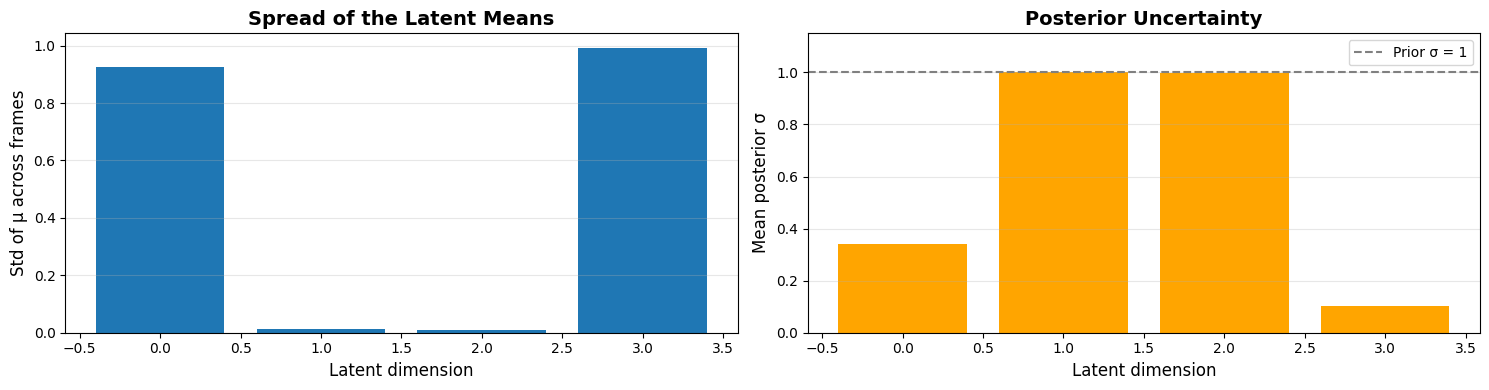

Active dimensions (mean σ < 0.5): [0, 3]


In [6]:
std_mu = mu.reshape(-1, mu.shape[-1]).std(axis=0)
mean_sigma = np.exp(0.5 * logvar).reshape(-1, mu.shape[-1]).mean(axis=0)
active = np.nonzero(mean_sigma < 0.5)[0]

dims = np.arange(mu.shape[-1])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].bar(dims, std_mu)
axes[0].set_xlabel('Latent dimension', fontsize=12)
axes[0].set_ylabel('Std of μ across frames', fontsize=12)
axes[0].set_title('Spread of the Latent Means', fontsize=14, fontweight='bold')

axes[1].bar(dims, mean_sigma, color='orange')
axes[1].axhline(1.0, linestyle='--', color='gray', label='Prior σ = 1')
axes[1].set_xlabel('Latent dimension', fontsize=12)
axes[1].set_ylabel('Mean posterior σ', fontsize=12)
axes[1].set_title('Posterior Uncertainty', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 1.15)
axes[1].legend()

for ax in axes:
    ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Active dimensions (mean σ < 0.5): {active.tolist()}")

### **Valid Transitions**

A JEPA sample with context length $k$ is $(z_{t-k+1}, \dots, z_t, a_t) \rightarrow z_{t+1}$. It is only valid when no reset happens inside the window, i.e. `dones[t-k+1 : t+1]` are all `False`. Because random actions make the pole fall every ~10 steps, the sub-episodes are short and each extra context step removes roughly one sample per sub-episode.

Resets: 24,266 (9.7% of steps)
Sub-episode length: median 10, 95th pct 16, max 28

context_len=1: 225,330 valid transitions
context_len=2: 200,742 valid transitions
context_len=3: 176,208 valid transitions
context_len=4: 151,721 valid transitions


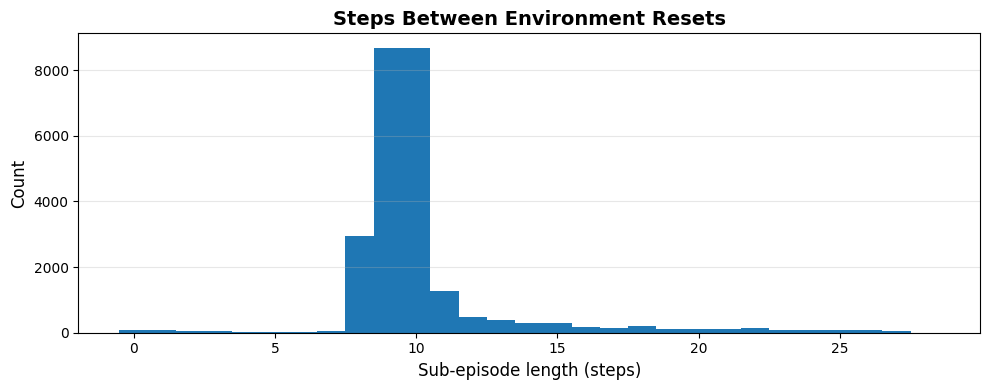

In [7]:
# Sub-episode lengths (steps between resets)
lengths = []
for ep_dones in dones:
    boundaries = np.r_[-1, np.nonzero(ep_dones)[0], dones.shape[1] - 1]
    lengths.extend(np.diff(boundaries))
lengths = np.array(lengths)

print(f"Resets: {dones.sum():,} ({dones.mean():.1%} of steps)")
print(f"Sub-episode length: median {np.median(lengths):.0f}, "
      f"95th pct {np.percentile(lengths, 95):.0f}, max {lengths.max()}")
print()
for k in (1, 2, 3, 4):
    print(f"context_len={k}: {len(JEPADataset(LATENT_PATH, context_len=k)):,} valid transitions")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lengths, bins=np.arange(lengths.max() + 2) - 0.5)
ax.set_xlabel('Sub-episode length (steps)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Steps Between Environment Resets', fontsize=14, fontweight='bold')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### **Latent Trajectories**

The active dimensions over the first 100 steps of an episode. Dotted lines mark resets: the latents evolve smoothly within a sub-episode and jump at each reset, which is exactly what the predictor must not be trained on.

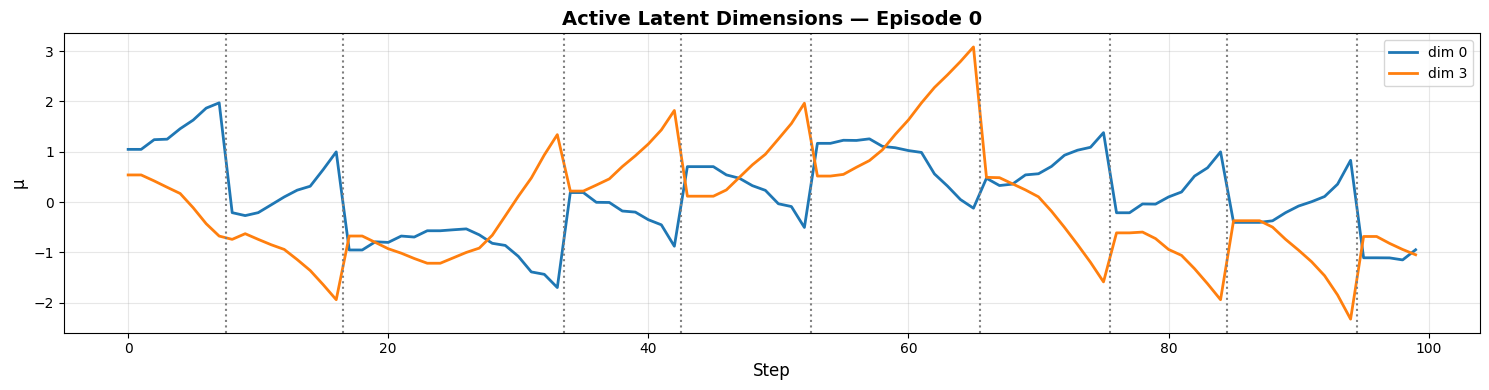

In [8]:
episode, steps = 0, 100
fig, ax = plt.subplots(figsize=(15, 4))
for d in active:
    ax.plot(mu[episode, :steps, d], linewidth=2, label=f'dim {d}')
for t in np.nonzero(dones[episode, :steps])[0]:
    ax.axvline(t + 0.5, linestyle=':', color='gray')
ax.set_xlabel('Step', fontsize=12)
ax.set_ylabel('μ', fontsize=12)
ax.set_title(f'Active Latent Dimensions — Episode {episode}', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### **Decoding the Stored Latents**

Sanity check: decoding the stored $\mu_t$ should reproduce the original frames (up to VAE reconstruction quality).

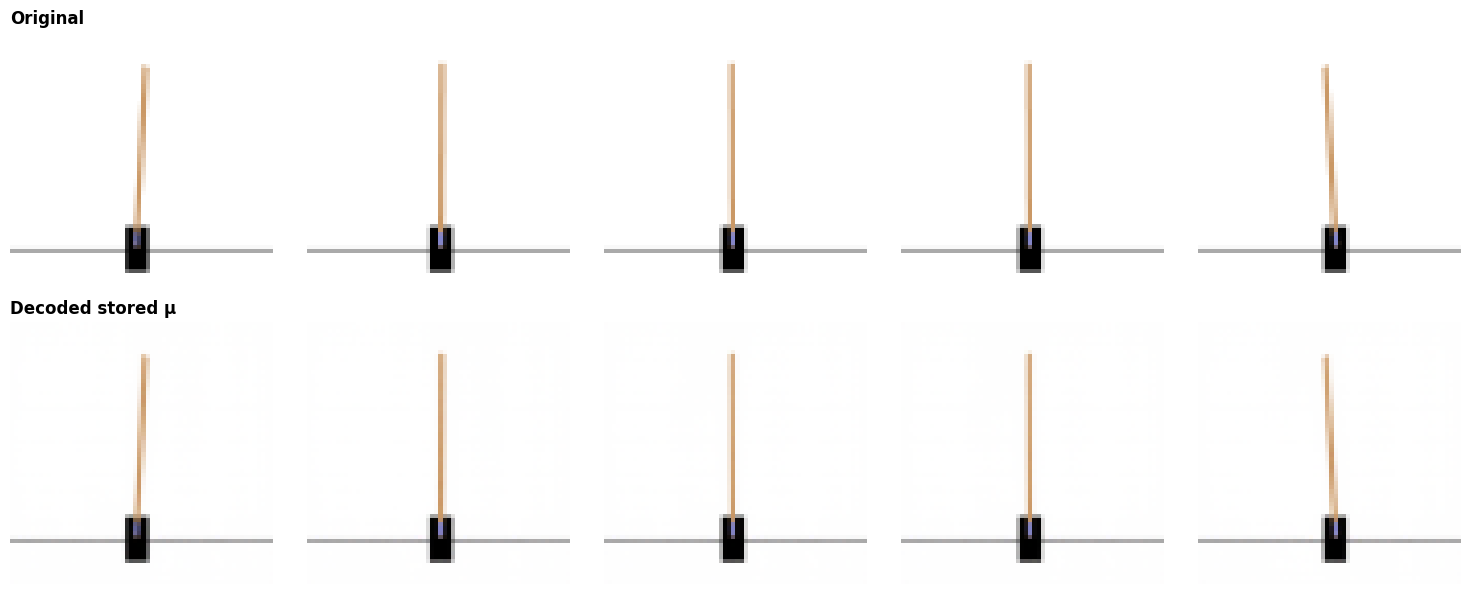

In [9]:
rng = np.random.default_rng(42)
samples = [(int(e), int(t)) for e, t in zip(rng.integers(0, mu.shape[0], 5), rng.integers(0, mu.shape[1], 5))]

with h5py.File(H5_PATH, 'r') as h5f:
    originals = np.stack([h5f['images'][e, t] for e, t in samples])

with torch.no_grad():
    stored_mu = torch.from_numpy(np.stack([mu[e, t] for e, t in samples])).to(DEVICE)
    decoded = vae.decode(stored_mu).cpu().permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    axes[0, i].imshow(originals[i])
    axes[1, i].imshow(decoded[i])
    axes[0, i].axis('off')
    axes[1, i].axis('off')
axes[0, 0].set_title('Original', fontsize=12, fontweight='bold', loc='left')
axes[1, 0].set_title('Decoded stored μ', fontsize=12, fontweight='bold', loc='left')
plt.tight_layout()
plt.show()

## **Summary and Next Steps**
---

✓ Encoded every frame of `vae_data.h5` into $(\mu, \log\sigma^2)$ with the trained VAE

✓ Saved the latents, actions, rewards and resets to `data/jepa/vae_latents.h5`

✓ Checked which latent dimensions the VAE actually uses and how many transitions are valid for each context length

### **Next Steps**

- **JEPA predictor** (`notebooks/2-vae/3-vae_jepa.ipynb`): train $(z_{t-k+1:t}, a_t) \rightarrow z_{t+1}$ on this dataset
- **Transfer learning**: `encode_dataset` accepts any encoder with an `encode(x) -> (mu, logvar)` method, so the ResNet encoder can produce a comparable latent file